In [20]:
# pregunta 1
import pandas as pd
import pandas as pd
df = pd.read_csv("https://raw.githubusercontent.com/jorgermzg15/data-files/refs/heads/main/Housing.csv")
print(df.select_dtypes(include="number").shape[1])   
print(df.select_dtypes(exclude="number").shape[1])   

6
7


In [21]:
# pregunta 2 
# ahora crea un split de los datos del 20% en el conjunto de test, y usando random_state=42 creando las variables X_train, X_test, y_test y y_train.
# ver las variables
df.info()
df.isnull().sum()


<class 'pandas.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   price             545 non-null    int64
 1   area              545 non-null    int64
 2   bedrooms          545 non-null    int64
 3   bathrooms         545 non-null    int64
 4   stories           545 non-null    int64
 5   mainroad          545 non-null    str  
 6   guestroom         545 non-null    str  
 7   basement          545 non-null    str  
 8   hotwaterheating   545 non-null    str  
 9   airconditioning   545 non-null    str  
 10  parking           545 non-null    int64
 11  prefarea          545 non-null    str  
 12  furnishingstatus  545 non-null    str  
dtypes: int64(6), str(7)
memory usage: 55.5 KB


price               0
area                0
bedrooms            0
bathrooms           0
stories             0
mainroad            0
guestroom           0
basement            0
hotwaterheating     0
airconditioning     0
parking             0
prefarea            0
furnishingstatus    0
dtype: int64

In [22]:
numericas = df.select_dtypes(include="number").columns.tolist()
categoricas = df.select_dtypes(exclude="number").columns.tolist()
print(numericas)
print(categoricas)

['price', 'area', 'bedrooms', 'bathrooms', 'stories', 'parking']
['mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'prefarea', 'furnishingstatus']


In [23]:
for c in categoricas:
    print(c, df[c].unique().tolist())

mainroad ['yes', 'no']
guestroom ['no', 'yes']
basement ['no', 'yes']
hotwaterheating ['no', 'yes']
airconditioning ['yes', 'no']
prefarea ['yes', 'no']
furnishingstatus ['furnished', 'semi-furnished', 'unfurnished']


In [24]:
binarias = [c for c in categoricas if set(df[c].unique()) == {'yes', 'no'}]
for c in binarias:
    df[c] = df[c].map({'yes': 1, 'no': 0})

df = pd.get_dummies(df, columns=['furnishingstatus'], drop_first=True)

In [25]:
from sklearn.model_selection import train_test_split

X = df.drop(columns='price')
y = df['price']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)

(436, 13) (109, 13) (436,) (109,)


In [26]:
# Pregunta 5
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error

lr = LinearRegression()
lr.fit(X_train, y_train)
y_pred_lr = lr.predict(X_test)

print("R2_test:", r2_score(y_test, y_pred_lr))
print("MAE_test:", mean_absolute_error(y_test, y_pred_lr))

R2_test: 0.6529242642153185
MAE_test: 970043.4039201637


In [27]:
# Pregunta 6
import numpy as np
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error

dt = DecisionTreeRegressor(random_state=42)
dt.fit(X_train, y_train)
y_pred_dt = dt.predict(X_test)

rmse_dt = np.sqrt(mean_squared_error(y_test, y_pred_dt))
print("RMSE_test:", rmse_dt)

RMSE_test: 1625669.904259373


## Caso 2 ##

In [28]:
# Problema 8
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv("https://raw.githubusercontent.com/jorgermzg15/data-files/refs/heads/main/UCI_Credit_Card.csv", index_col="ID")

df = df.rename(columns={'default.payment.next.month': 'IsDefaulter'})
df['IsDefaulter'].value_counts()

IsDefaulter
0    23364
1     6636
Name: count, dtype: int64

In [29]:
# Problema 9
df['EDUCATION'] = df['EDUCATION'].replace({0: 4, 5: 4, 6: 4})
df['EDUCATION'].value_counts().sort_index()

EDUCATION
1    10585
2    14030
3     4917
4      468
Name: count, dtype: int64

In [30]:
# Problema 10
df['MARRIAGE'] = df['MARRIAGE'].replace({0: 3})
df['MARRIAGE'].value_counts().sort_index()

MARRIAGE
1    13659
2    15964
3      377
Name: count, dtype: int64

In [31]:
# Problema 11
df[df['IsDefaulter'] == 1]['AGE'].mean()

np.float64(35.72573839662447)

In [32]:
# Problema 12
df = pd.get_dummies(df, columns=['EDUCATION', 'MARRIAGE'])


In [33]:
dummies = [c for c in df.columns if c.startswith(('EDUCATION_', 'MARRIAGE_'))]
print(dummies)
print(len(dummies))
print(df.shape)

['EDUCATION_1', 'EDUCATION_2', 'EDUCATION_3', 'EDUCATION_4', 'MARRIAGE_1', 'MARRIAGE_2', 'MARRIAGE_3']
7
(30000, 29)


In [34]:
# Problema 13
pays = ['PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6']
df = pd.get_dummies(df, columns=pays, drop_first=True)

dummies_pay = [c for c in df.columns if c.startswith(tuple(p + '_' for p in pays))]
print(len(dummies_pay))
print(df.shape)

58
(30000, 81)


In [35]:
# Problema 14
print(df.columns.tolist())
print(len(df.columns))
print('ID' in df.columns)
print(df.index.name)

['LIMIT_BAL', 'SEX', 'AGE', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6', 'IsDefaulter', 'EDUCATION_1', 'EDUCATION_2', 'EDUCATION_3', 'EDUCATION_4', 'MARRIAGE_1', 'MARRIAGE_2', 'MARRIAGE_3', 'PAY_0_-1', 'PAY_0_0', 'PAY_0_1', 'PAY_0_2', 'PAY_0_3', 'PAY_0_4', 'PAY_0_5', 'PAY_0_6', 'PAY_0_7', 'PAY_0_8', 'PAY_2_-1', 'PAY_2_0', 'PAY_2_1', 'PAY_2_2', 'PAY_2_3', 'PAY_2_4', 'PAY_2_5', 'PAY_2_6', 'PAY_2_7', 'PAY_2_8', 'PAY_3_-1', 'PAY_3_0', 'PAY_3_1', 'PAY_3_2', 'PAY_3_3', 'PAY_3_4', 'PAY_3_5', 'PAY_3_6', 'PAY_3_7', 'PAY_3_8', 'PAY_4_-1', 'PAY_4_0', 'PAY_4_1', 'PAY_4_2', 'PAY_4_3', 'PAY_4_4', 'PAY_4_5', 'PAY_4_6', 'PAY_4_7', 'PAY_4_8', 'PAY_5_-1', 'PAY_5_0', 'PAY_5_2', 'PAY_5_3', 'PAY_5_4', 'PAY_5_5', 'PAY_5_6', 'PAY_5_7', 'PAY_5_8', 'PAY_6_-1', 'PAY_6_0', 'PAY_6_2', 'PAY_6_3', 'PAY_6_4', 'PAY_6_5', 'PAY_6_6', 'PAY_6_7', 'PAY_6_8']
81
False
ID


In [36]:
df = df.drop(columns=['ID'], errors='ignore')
print(df.shape)

(30000, 81)


In [37]:
# Problema 15
from sklearn.model_selection import train_test_split

X = df.drop(columns='IsDefaulter')
y = df['IsDefaulter']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.33, random_state=42, stratify=df.IsDefaulter
)

print(len(X_train))

20100


In [40]:
# Pregunta 16
# Escala los datos con StandardScaler()
# Ajusta una regresión logística con los paramétros solicitados en el conjunto de entrenamiento balanceado, transformado y escalado.
# ¿Cuál es el accuracy en test redondeando a 2 decimales?

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)   # fit solo con train
X_test_s = scaler.transform(X_test)         # test solo se transforma

log_reg = LogisticRegression(C=10, penalty='l2', random_state=42,
                             class_weight='balanced', max_iter=2000)
log_reg.fit(X_train_s, y_train)

y_pred_lr = log_reg.predict(X_test_s)
print(round(accuracy_score(y_test, y_pred_lr), 2))


/workspaces/aprendizaje-no-supervisado-595879/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


0.78


In [42]:
# Pregunta 17 
from sklearn.metrics import recall_score, confusion_matrix, classification_report

print(recall_score(y_test, y_pred_lr))

0.5657534246575342


In [43]:
# pregunta 18
from sklearn.metrics import precision_score
print(precision_score(y_test, y_pred_lr))

0.4932324840764331


In [45]:
# Pregunta 19
#Matriz de confusión
cm = confusion_matrix(y_test, y_pred_lr)
print(cm)

[[6437 1273]
 [ 951 1239]]


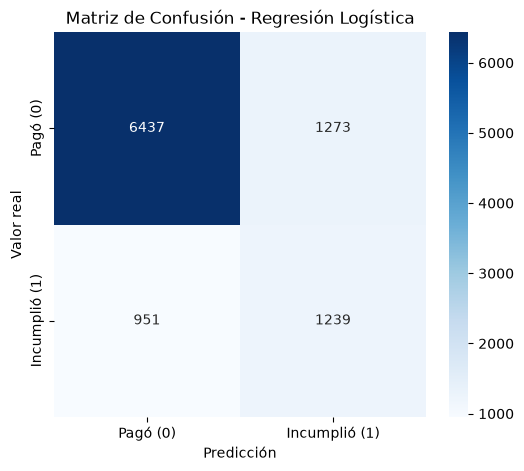

In [46]:
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Pagó (0)', 'Incumplió (1)'],
            yticklabels=['Pagó (0)', 'Incumplió (1)'])
plt.xlabel('Predicción')
plt.ylabel('Valor real')
plt.title('Matriz de Confusión - Regresión Logística')
plt.show()

In [47]:
# pregunta 21
from sklearn.tree import DecisionTreeClassifier

tree = DecisionTreeClassifier(max_depth=20, min_samples_split=0.1,
                              random_state=42, class_weight='balanced')
tree.fit(X_train, y_train)          # datos SIN escalar
y_pred_tree = tree.predict(X_test)

print(accuracy_score(y_test, y_pred_tree))

0.7144444444444444


In [48]:
from sklearn.metrics import f1_score

print("Accuracy:", accuracy_score(y_test, y_pred_tree))
print("Recall:", recall_score(y_test, y_pred_tree))
print("Precision:", precision_score(y_test, y_pred_tree))
print("F1:", f1_score(y_test, y_pred_tree))
print(confusion_matrix(y_test, y_pred_tree))
print(classification_report(y_test, y_pred_tree))

Accuracy: 0.7144444444444444
Recall: 0.6648401826484018
Precision: 0.41025641025641024
F1: 0.5074054713364697
[[5617 2093]
 [ 734 1456]]
              precision    recall  f1-score   support

           0       0.88      0.73      0.80      7710
           1       0.41      0.66      0.51      2190

    accuracy                           0.71      9900
   macro avg       0.65      0.70      0.65      9900
weighted avg       0.78      0.71      0.73      9900



## Caso 3 ##

In [49]:
# Pregunta 23
df = pd.read_csv("https://raw.githubusercontent.com/jorgermzg15/data-files/refs/heads/main/College_Data.csv")
X = df.drop(columns='College')

In [51]:
# Pregunta 27 
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

X = df.drop(columns='College')
X['Private'] = X['Private'].map({'Yes': 1, 'No': 0})   # K-Means no acepta texto

kmeans = KMeans(n_clusters=2, random_state=42)
labels = kmeans.fit_predict(X)                          # sin escalar

print(silhouette_score(X, labels))

0.5365983141181537


In [52]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN

X = df.drop(columns='College')
X['Private'] = X['Private'].map({'Yes': 1, 'No': 0})

X_scaled = StandardScaler().fit_transform(X)

dbscan = DBSCAN(eps=2.0, min_samples=5)
labels = dbscan.fit_predict(X_scaled)

n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
print(n_clusters)
print(pd.Series(labels).value_counts())

3
 0    416
-1    289
 2     64
 1      8
Name: count, dtype: int64


In [53]:
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

pca = PCA(n_components=0.8, random_state=42)
X_pca = pca.fit_transform(X_scaled)

print(pca.n_components_)                        # 6
print(pca.explained_variance_ratio_.sum())      # 0.8081

kmeans = KMeans(n_clusters=3, random_state=42)
labels_pca = kmeans.fit_predict(X_pca)

print(silhouette_score(X_pca, labels_pca))

6
0.8080739366716876
0.29208443639972653
